# Lien entre le vent et les traumatismes

### Données météo

In [2]:
import requests
import pandas as pd
import re

"""
r = requests.get(
    "https://www.data.gouv.fr/api/1/datasets/donnees-climatologiques-de-base-quotidiennes/",
    headers={"X-Fields": "id,title,resources{title,format,type,latest}"},
    timeout=30,
)
"""
r = requests.get(
    "https://www.data.gouv.fr/api/1/datasets/donnees-climatologiques-de-base-quotidiennes/",
    headers={"X-Fields": "id,title,resources{title,format,type,latest}"},
)

fiche = r.json()
# for i in range(len(fiche['resources'])):
#     print(fiche['resources'][i]['title'])

pattern = r'QUOT_departement_\d+_periode_1950-2024_RR-T-Vent'

fichiers_interet = [fiche['resources'][i] for i in range(len(fiche['resources'])) if re.fullmatch(pattern, fiche['resources'][i]['title']) ] ## On filtre sur les jeux de données qui nous intéressent
##liste de dictionnaires
##inclu les DROM et les COM

# print(fichiers_interet[0]['latest'])

variables_vent_1 = ['NUM_POSTE', 'AAAAMMJJ', 'FFM', 'FXI3S'] ##, 'FF2M', 'FXY', 'DXY', 'FXI','DXI', 'FXI2', 'DXI2', 'FXI3S', 'DXI3S'
donnees_vent = []
nbre_departement = 0
for i in range(len(fichiers_interet)): ##len(fichiers_interet)
    print(f"nombre de départements importés : {nbre_departement}", end="\r")
    donnees_interet = pd.read_csv(fichiers_interet[i]['latest'],sep=';',dtype = {'NUM_POSTE' : str}, usecols = variables_vent_1, compression="gzip")  ##, parse_dates=["AAAAMMJJ"], date_format="%Y%m%d
    donnes_interet_filtre = donnees_interet[donnees_interet["AAAAMMJJ"] >= 20160101]
    donnees_vent.append(donnes_interet_filtre)
    nbre_departement += 1
print(f"nombre de départements importés : {len(fichiers_interet)}")

meteoDF = pd.concat(donnees_vent, ignore_index=True)

meteoDF.info()
display(meteoDF)

nombre de départements importés : 106
<class 'pandas.DataFrame'>
RangeIndex: 10273735 entries, 0 to 10273734
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   NUM_POSTE  str    
 1   AAAAMMJJ   int64  
 2   FFM        float64
 3   FXI3S      float64
dtypes: float64(2), int64(1), str(1)
memory usage: 393.1 MB


,NUM_POSTE,AAAAMMJJ,FFM,FXI3S
0,01014002,20160101,2.0,14.2
1,01014002,20160102,1.1,10.2
2,01014002,20160103,2.6,17.4
3,01014002,20160104,2.9,12.3
4,01014002,20160105,1.8,7.4
...,...,...,...,...
10273730,99138001,20170727,NaN,NaN
10273731,99138001,20170728,NaN,NaN
10273732,99138001,20170729,NaN,NaN
10273733,99138001,20170730,NaN,NaN


In [3]:

meteoDF = meteoDF.rename(columns = {'AAAAMMJJ' : 'DATE'})
meteoDF['DATE'] = pd.to_datetime(meteoDF['DATE'], format = '%Y%m%d' )
meteoDF = meteoDF.rename(columns={"FFM": "vent_moyen_ms","FXI3S": "rafale_max_ms"})

meteoDF['dep'] = meteoDF['NUM_POSTE'].str[:2]
#meteoDF.loc[meteoDF['dep'].astype(int) > 95, "dep"] = meteoDF.loc[df_final1['dep'].astype(int) > 95, "NUM_POSTE"].str[:3]
meteoDF["semaine_iso"] = meteoDF["DATE"].dt.isocalendar().week
meteoDF["annee_iso"] = meteoDF["DATE"].dt.isocalendar().year
meteoDF["cle_semaine"] = list(zip(meteoDF["dep"], meteoDF["semaine_iso"], meteoDF["annee_iso"]))
meteoDF = meteoDF[["DATE", "annee_iso", "semaine_iso", "dep", "cle_semaine", "vent_moyen_ms", "rafale_max_ms"]]

meteo_jour = meteoDF.groupby(['DATE', 'dep'])[['vent_moyen_ms', 'rafale_max_ms']].mean().reset_index()
meteo_sem = meteoDF.groupby(['cle_semaine'])[['vent_moyen_ms', 'rafale_max_ms']].mean().reset_index()


/tmp/ipykernel_31788/627767387.py:2: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  meteoDF['DATE'] = pd.to_datetime(meteoDF['DATE'], format = '%Y%m%d' )


In [4]:
meteo_sem.head()

,cle_semaine,vent_moyen_ms,rafale_max_ms
0,"(01, 1, 2016)",1.919048,9.273810
1,"(01, 1, 2017)",1.843590,7.479487
2,"(01, 1, 2018)",2.392500,11.412500
3,"(01, 1, 2019)",2.421951,8.783333
4,"(01, 1, 2020)",1.230303,5.278571


In [5]:
meteo_jour.head()

,DATE,dep,vent_moyen_ms,rafale_max_ms
0,2016-01-01,01,1.633333,8.183333
1,2016-01-01,02,3.914286,11.042857
2,2016-01-01,03,2.460000,8.940000
3,2016-01-01,04,1.133333,5.925000
4,2016-01-01,05,1.482353,6.641667


### Données traumatismes

In [6]:
import pandas as pd

bobos = pd.read_parquet("https://minio.lab.sspcloud.fr/jvalade/projet_2A_S1/traumatisme-passages-aux-urgences-et-actes-sos-medecins-departement.parquet")
nb_hospi = pd.read_parquet("https://minio.lab.sspcloud.fr/jvalade/projet_2A_S1/series_longues_passages_urgences_2017_2023.parquet")

nb_hospi["date"] = pd.to_datetime(nb_hospi["date"])
nb_hospi["semaine"] = nb_hospi["date"].dt.isocalendar().week

bobos["date_complet"] = pd.to_datetime(bobos["date_complet"])
bobos["semaine"] = bobos["date_complet"].dt.isocalendar().week

nb_hospi["cle_semaine"] = list(zip(nb_hospi["dep"], nb_hospi["semaine"], nb_hospi["date"].dt.isocalendar().year)) #on utilise zip pour concaténer les colonnes selon l'axis 1
bobos["cle_semaine"] = list(zip(bobos["dep"], bobos["semaine"], bobos["date_complet"].dt.isocalendar().year))

nb_hospi_semaine = nb_hospi.groupby("cle_semaine")[["nb_passages"]].sum()

nb_bobos = bobos.merge(nb_hospi_semaine, on="cle_semaine", how= 'inner')

nb_bobos = nb_bobos[nb_bobos["sursaud_cl_age_gene"] == "Tous âges"]

nb_bobos["nb_traumas"] = nb_bobos["taux_passages_trauma_sau"] * nb_bobos["nb_passages"] / 100_000 #le taux de passage correspond au nombre pour 100 000 passages
nb_bobos = nb_bobos[["cle_semaine", "date_complet", "dep", "nb_traumas"]] #on ne garde que les variables d'intérêt

nb_bobos.head()


,cle_semaine,date_complet,dep,nb_traumas
1,"(75, 52, 2023)",2023-12-25,75,2001.502367
4,"(89, 52, 2023)",2023-12-25,89,501.896406
7,"(69, 52, 2023)",2023-12-25,69,2145.691326
14,"(14, 52, 2023)",2023-12-25,14,992.732680
16,"(15, 52, 2023)",2023-12-25,15,210.902970


### Données crime

In [7]:
DEPARTMENTS = {
    '01': 'Ain', 
    '02': 'Aisne', 
    '03': 'Allier', 
    '04': 'Alpes-de-Haute-Provence', 
    '05': 'Hautes-Alpes',
    '06': 'Alpes-Maritimes', 
    '07': 'Ardèche', 
    '08': 'Ardennes', 
    '09': 'Ariège', 
    '10': 'Aube', 
    '11': 'Aude',
    '12': 'Aveyron', 
    '13': 'Bouches-du-Rhône', 
    '14': 'Calvados', 
    '15': 'Cantal', 
    '16': 'Charente',
    '17': 'Charente-Maritime', 
    '18': 'Cher', 
    '19': 'Corrèze', 
    '2A': 'Corse-du-Sud', 
    '2B': 'Haute-Corse',
    '21': 'Côte-d\'Or', 
    '22': 'Côtes-d\'Armor', 
    '23': 'Creuse', 
    '24': 'Dordogne', 
    '25': 'Doubs', 
    '26': 'Drôme',
    '27': 'Eure', 
    '28': 'Eure-et-Loir', 
    '29': 'Finistère', 
    '30': 'Gard', 
    '31': 'Haute-Garonne', 
    '32': 'Gers',
    '33': 'Gironde', 
    '34': 'Hérault', 
    '35': 'Ille-et-Vilaine', 
    '36': 'Indre', 
    '37': 'Indre-et-Loire',
    '38': 'Isère', 
    '39': 'Jura', 
    '40': 'Landes', 
    '41': 'Loir-et-Cher', 
    '42': 'Loire', 
    '43': 'Haute-Loire',
    '44': 'Loire-Atlantique', 
    '45': 'Loiret', 
    '46': 'Lot', 
    '47': 'Lot-et-Garonne', 
    '48': 'Lozère',
    '49': 'Maine-et-Loire', 
    '50': 'Manche', 
    '51': 'Marne', 
    '52': 'Haute-Marne', 
    '53': 'Mayenne',
    '54': 'Meurthe-et-Moselle', 
    '55': 'Meuse', 
    '56': 'Morbihan', 
    '57': 'Moselle', 
    '58': 'Nièvre', 
    '59': 'Nord',
    '60': 'Oise', 
    '61': 'Orne', 
    '62': 'Pas-de-Calais', 
    '63': 'Puy-de-Dôme', 
    '64': 'Pyrénées-Atlantiques',
    '65': 'Hautes-Pyrénées', 
    '66': 'Pyrénées-Orientales', 
    '67': 'Bas-Rhin', 
    '68': 'Haut-Rhin', 
    '69': 'Rhône',
    '70': 'Haute-Saône', 
    '71': 'Saône-et-Loire', 
    '72': 'Sarthe', 
    '73': 'Savoie', 
    '74': 'Haute-Savoie',
    '75': 'Paris', 
    '76': 'Seine-Maritime', 
    '77': 'Seine-et-Marne', 
    '78': 'Yvelines', 
    '79': 'Deux-Sèvres',
    '80': 'Somme', 
    '81': 'Tarn', 
    '82': 'Tarn-et-Garonne', 
    '83': 'Var', 
    '84': 'Vaucluse', 
    '85': 'Vendée',
    '86': 'Vienne', 
    '87': 'Haute-Vienne', 
    '88': 'Vosges', 
    '89': 'Yonne', 
    '90': 'Territoire de Belfort',
    '91': 'Essonne', 
    '92': 'Hauts-de-Seine', 
    '93': 'Seine-Saint-Denis', 
    '94': 'Val-de-Marne', 
    '95': 'Val-d\'Oise',
    '971': 'Guadeloupe', 
    '972': 'Martinique', 
    '973': 'Guyane', 
    '974': 'La Réunion', 
    '976': 'Mayotte',
}


In [8]:
import requests
import bs4
import pandas as pd

!pip install lxml --quiet

url = "https://fr.wikipedia.org/wiki/Liste_d'affaires_criminelles_fran%C3%A7aises_depuis_1900"

req = requests.get(url, headers={"User-Agent":"School Data Science Project"})

request_text = req.content
page = bs4.BeautifulSoup(request_text, "lxml")

tableaux = page.find_all('table', {'class':'wikitable sortable'})

faitsDiv = list()
for tableau in tableaux :
    table_body = tableau.find('tbody')
    rows = table_body.find_all('tr')
    liste = list()
    for row in rows:
        cols = row.find_all('td')
        cols = [ele.text.strip() for ele in cols]
        if len(cols) > 0 : 
            liste.append(cols)
    faitsDiv.append(liste)

liste_dataf = list()
for tableau in faitsDiv :
    liste_dataf.append(pd.DataFrame(tableau))

liste_colonnes = list()

for tableau in tableaux :
    table_body = tableau.find('tbody')
    rows = table_body.find_all('tr')
    for row in rows:
        cols = row.find_all('th')
        if len(cols) > 0 : 
            cols = [ele.get_text(separator=' ').strip().title() for ele in cols]
            liste_colonnes.append(cols)

for i in range(len(liste_dataf)):
    liste_dataf[i].columns = liste_colonnes[i]

faitsDivDF = pd.concat(liste_dataf)
faitsDivDF = faitsDivDF.reset_index(drop=True)

faitsDivDF = faitsDivDF[["Département(S) [ Note 2 ]", "Résumé"]]

import re

import pandas as pd

MOIS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet",
        "août", "septembre", "octobre", "novembre", "décembre"]
MOTIF = re.compile(r"(\d{1,2})(?:er)? (" + "|".join(MOIS) + r") (\d{4})")


def extraire_date(texte):
    """
    Renvoie la première date rencontrée au format JJ-MM-AAAA, Nan si pas de date dans le texte
    """
    m = MOTIF.search(str(texte))
    if not m:
        return None
    jour, mois, annee = m.groups()
    return f"{int(jour):02d}-{MOIS.index(mois) + 1:02d}-{annee}"

faitsDivDF = faitsDivDF[["Département(S) [ Note 2 ]", "Résumé"]]
faitsDivDF.columns = ["Département" , "Résumé"]

for i in range(len(faitsDivDF)) : 
    faitsDivDF.loc[i, "date"] = extraire_date(faitsDivDF.loc[i, "Résumé"])

departement_df = pd.DataFrame.from_dict(DEPARTMENTS, orient = 'index', columns=["Département"])
departement_df = departement_df.reset_index()
departement_df.columns = ["Numéro", "Département"]

faitsDivDF = faitsDivDF.merge(departement_df, on="Département", how = "inner")

faitsDivDF = faitsDivDF.dropna()
faitsDivDF["date"] = pd.to_datetime(faitsDivDF["date"], format= f'%d-%m-%Y')
faitsDivDF.columns = ["Département", "Résumé", "DATE", "dep"]
faitsDivDF.head()

/tmp/ipykernel_31788/1873521599.py:30: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  liste_dataf.append(pd.DataFrame(tableau))


,Département,Résumé,DATE,dep
1,Gironde,"Le 6 février 1907 à Langon, assassinat crapule...",1907-02-06,33
2,Finistère,"Le 4 février 1914, le corps de Louis Cadiou es...",1914-02-04,29
3,Paris,"Assassinat du directeur du Figaro, Gaston Calm...",1914-03-16,75
4,Paris,"Assassinat du leader socialiste Jean Jaurès, l...",1914-07-31,75
7,Paris,Assassinat du commissionnaire Georges Bassarab...,1920-07-31,75


### Jointure des données

In [27]:
ventBobos = meteo_sem.merge(nb_bobos, on = "cle_semaine", how = "inner")

ventBobos.head()
display(ventBobos.info())

<class 'pandas.DataFrame'>
RangeIndex: 14508 entries, 0 to 14507
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype        
---  ------         --------------  -----        
 0   cle_semaine    14508 non-null  object       
 1   vent_moyen_ms  14040 non-null  float64      
 2   rafale_max_ms  14040 non-null  float64      
 3   date_complet   14508 non-null  datetime64[s]
 4   dep            14508 non-null  str          
 5   nb_traumas     14508 non-null  float64      
dtypes: datetime64[s](1), float64(3), object(1), str(1)
memory usage: 710.3+ KB


None

In [10]:
ventCrime = meteo_jour.merge(faitsDivDF, on = ["DATE", "dep"], how = "inner")

ventCrime.head()

,DATE,dep,vent_moyen_ms,rafale_max_ms,Département,Résumé
0,2016-01-05,01,2.200000,8.883333,Ain,"Le 5 janvier 2016 à Ambérieu-en-Bugey, Anne-Ch..."
1,2016-03-13,71,4.057143,12.757143,Saône-et-Loire,"Le 13 mars 2016 à la Clayette, Valérie Bacot, ..."
2,2016-06-13,78,3.116667,8.250000,Yvelines,"Le 13 juin 2016 à Magnanville, assassinat d'un..."
3,2016-07-14,06,3.815000,18.342105,Alpes-Maritimes,"Le 14 juillet 2016 à Nice, Mohamed Lahouaiej-B..."
4,2016-07-26,76,2.585714,7.971429,Seine-Maritime,"Le 26 juillet 2016 à Saint-Étienne-du-Rouvray,..."


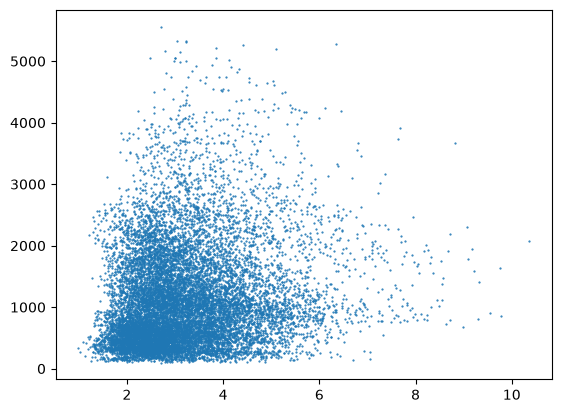

In [11]:
from matplotlib import pyplot as plt

x = ventBobos["vent_moyen_ms"]
y = ventBobos["nb_traumas"]

plt.scatter(x,y, s=0.3)
plt.show()


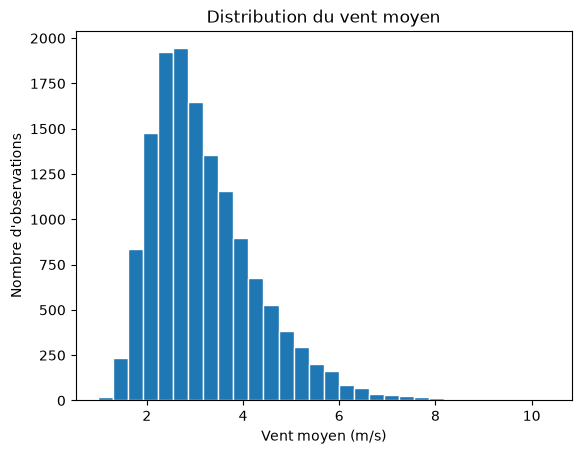

In [30]:

### Note : graphique à comparer avec les moyennes de vent, sinon inutile


from matplotlib import pyplot as plt

x = ventBobos["vent_moyen_ms"]
plt.hist(x, bins=30, edgecolor="white")
plt.title("Distribution du vent moyen")
plt.xlabel("Vent moyen (m/s)")
plt.ylabel("Nombre d'observations")
plt.show()


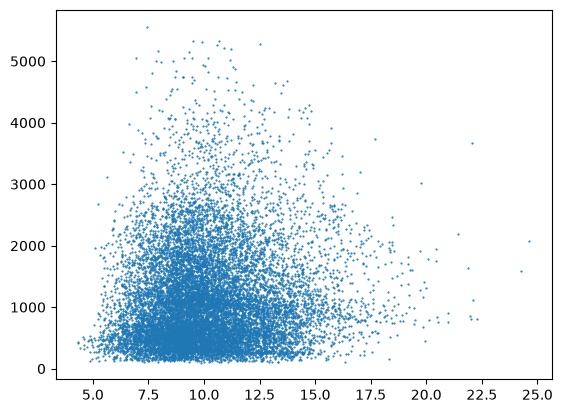

In [ ]:
x = ventBobos["rafale_max_ms"]
y = ventBobos["nb_traumas"]

plt.scatter(x,y, s=0.3)
plt.show()

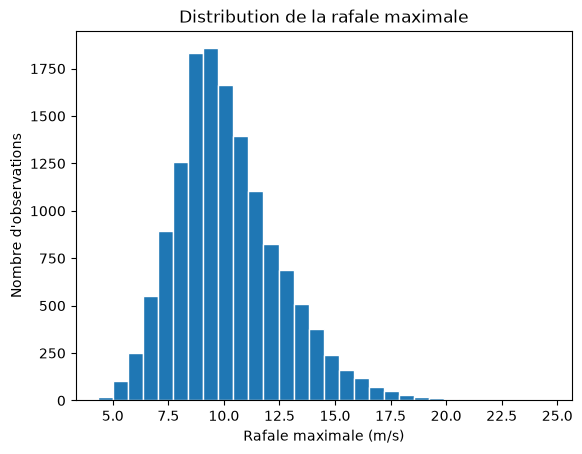

In [33]:
### Note : graphique à comparer avec les moyennes de vent

x = ventBobos["rafale_max_ms"]

plt.hist(x, bins=30, edgecolor="white")
plt.title("Distribution de la rafale maximale")
plt.xlabel("Rafale maximale (m/s)")
plt.ylabel("Nombre d'observations")
plt.show()

Il y a beaucoup d'observations les semaines de faible vent ainsi que d'observations dans la moyenne.\
On normalise ???